In [39]:
#from google.colab import drive
#drive.mount('/content/drive')

import pandas as pd

# Ensure 'Crimes_-_2001_to_Present.csv' is uploaded to your Google Drive
# and replace the path below with the correct one if needed.
df = pd.read_csv('crime_500k.csv')
print(df.head())
print(len(df))

         ID Case Number                    Date                  Block  IUCR  \
0  10224738    HY411648  09/05/2015 01:30:00 PM        043XX S WOOD ST  0486   
1  10224739    HY411615  09/04/2015 11:30:00 AM    008XX N CENTRAL AVE  0870   
2  11646166    JC213529  09/01/2018 12:01:00 AM  082XX S INGLESIDE AVE  0810   
3  10224740    HY411595  09/05/2015 12:45:00 PM      035XX W BARRY AVE  2023   
4  10224741    HY411610  09/05/2015 01:00:00 PM    0000X N LARAMIE AVE  0560   

  Primary Type              Description Location Description  Arrest  \
0      BATTERY  DOMESTIC BATTERY SIMPLE            RESIDENCE   False   
1        THEFT           POCKET-PICKING              CTA BUS   False   
2        THEFT                OVER $500            RESIDENCE   False   
3    NARCOTICS    POSS: HEROIN(BRN/TAN)             SIDEWALK    True   
4      ASSAULT                   SIMPLE            APARTMENT   False   

   Domestic  ...  Ward  Community Area  FBI Code  X Coordinate Y Coordinate  \
0      

In [40]:
import pandas as pd
df = df[[
    'Date',
    'Primary Type',
    'Latitude',
    'Longitude',
    'Arrest'
]]
df.columns = ['date', 'crime_type', 'lat', 'long', 'arrest']
df = df.dropna(subset=['lat', 'long'])
df['date'] = pd.to_datetime(df['date'])
df = df.drop_duplicates()
df = df.reset_index(drop=True)
print(df.shape)
print(df.head())
print(len(df))

/tmp/ipykernel_4968/1167401442.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['date'] = pd.to_datetime(df['date'])


(280456, 5)
                 date crime_type        lat       long  arrest
0 2015-09-05 13:30:00    BATTERY  41.815117 -87.670000   False
1 2015-09-04 11:30:00      THEFT  41.895080 -87.765400   False
2 2015-09-05 12:45:00  NARCOTICS  41.937406 -87.716650    True
3 2015-09-05 13:00:00    ASSAULT  41.881903 -87.755121   False
4 2015-09-05 10:55:00   BURGLARY  41.744379 -87.658431   False
280456


In [41]:
#FEATURE ENGINEERING
df['date'] = pd.to_datetime(df['date'])
df['hour'] = df['date'].dt.hour
df['day'] = df['date'].dt.day
df['month'] = df['date'].dt.month
df['year'] = df['date'].dt.year
df['weekday'] = df['date'].dt.weekday  # Monday=0, Sunday=6
def get_time_slot(hour):
    if 6 <= hour < 12:
        return 'morning'
    elif 12 <= hour < 18:
        return 'afternoon'
    elif 18 <= hour < 24:
        return 'evening'
    else:
        return 'night'

df['time_slot'] = df['hour'].apply(get_time_slot)
df['is_weekend'] = df['weekday'].apply(lambda x: 1 if x >= 5 else 0)
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['crime_type_encoded'] = le.fit_transform(df['crime_type'])
df['time_slot_encoded'] = LabelEncoder().fit_transform(df['time_slot'])
print(df.head())
print(df.columns)
print("Rows after feature engineering:", len(df))

                 date crime_type        lat       long  arrest  hour  day  \
0 2015-09-05 13:30:00    BATTERY  41.815117 -87.670000   False    13    5   
1 2015-09-04 11:30:00      THEFT  41.895080 -87.765400   False    11    4   
2 2015-09-05 12:45:00  NARCOTICS  41.937406 -87.716650    True    12    5   
3 2015-09-05 13:00:00    ASSAULT  41.881903 -87.755121   False    13    5   
4 2015-09-05 10:55:00   BURGLARY  41.744379 -87.658431   False    10    5   

   month  year  weekday  time_slot  is_weekend  crime_type_encoded  \
0      9  2015        5  afternoon           1                   2   
1      9  2015        4    morning           0                  32   
2      9  2015        5  afternoon           1                  18   
3      9  2015        5  afternoon           1                   1   
4      9  2015        5    morning           1                   3   

   time_slot_encoded  
0                  0  
1                  2  
2                  0  
3                  0  
4

In [ ]:
#VISUALIZATION(TABLEAU) - VISHNOI

In [42]:
df.isnull().sum()

,0
date,0
crime_type,0
lat,0
long,0
arrest,0
hour,0
day,0
month,0
year,0
weekday,0


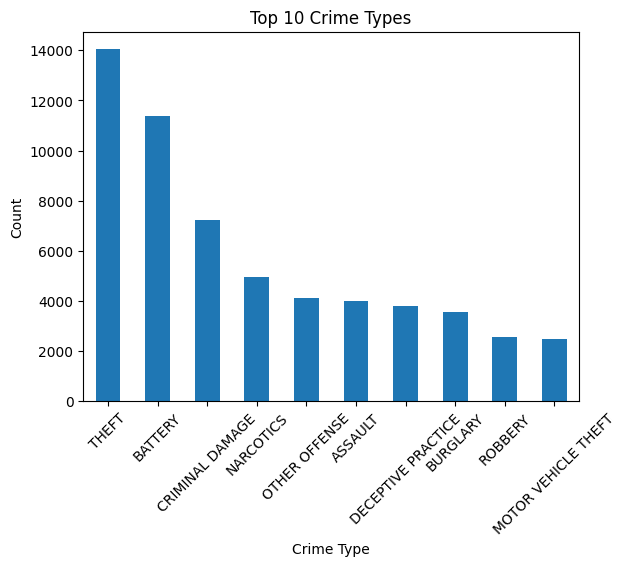

In [ ]:
import matplotlib.pyplot as plt  # For plotting graphs
import seaborn as sns            # For advanced visualization
# Plot top 10 crime types
df['crime_type'].value_counts().head(10).plot(kind='bar')
plt.title("Top 10 Crime Types")
plt.xlabel("Crime Type")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

In [ ]:
df.isnull().sum()

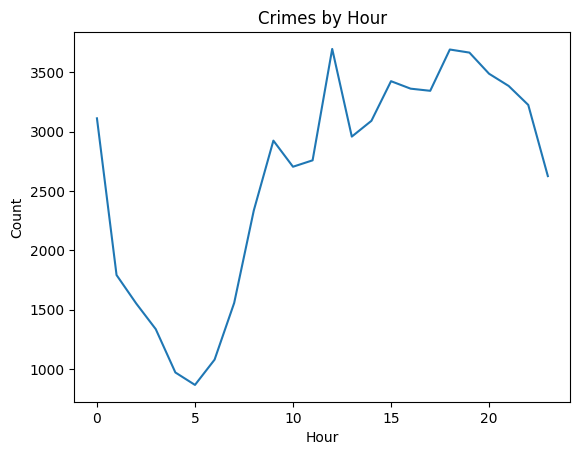

In [ ]:
# Plot number of crimes by hour
df['hour'].value_counts().sort_index().plot(kind='line')
plt.title("Crimes by Hour")
plt.xlabel("Hour")
plt.ylabel("Count")
plt.show()

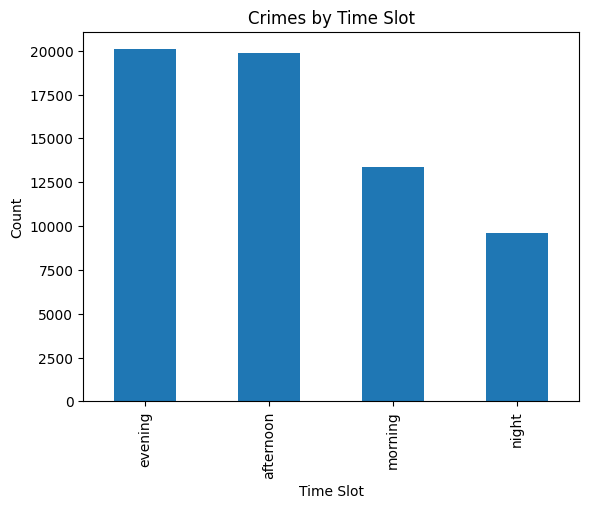

In [ ]:
# Plot crimes by time slot
df['time_slot'].value_counts().plot(kind='bar')
plt.title("Crimes by Time Slot")
plt.xlabel("Time Slot")
plt.ylabel("Count")
plt.show()

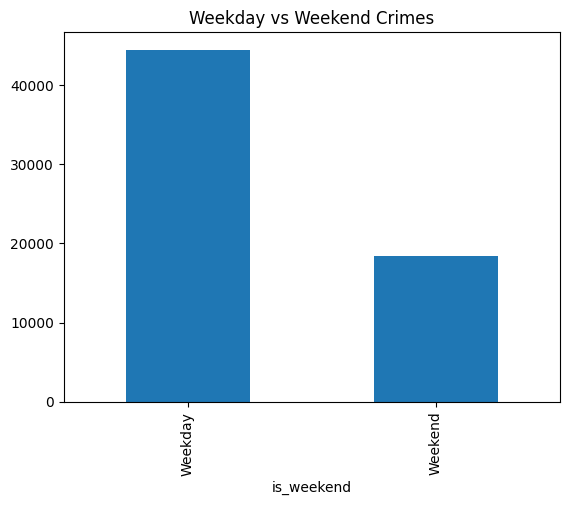

In [ ]:
# Compare weekday vs weekend crimes
df['is_weekend'].value_counts().plot(kind='bar')
plt.title("Weekday vs Weekend Crimes")
plt.xticks([0,1], ['Weekday','Weekend'])
plt.show()

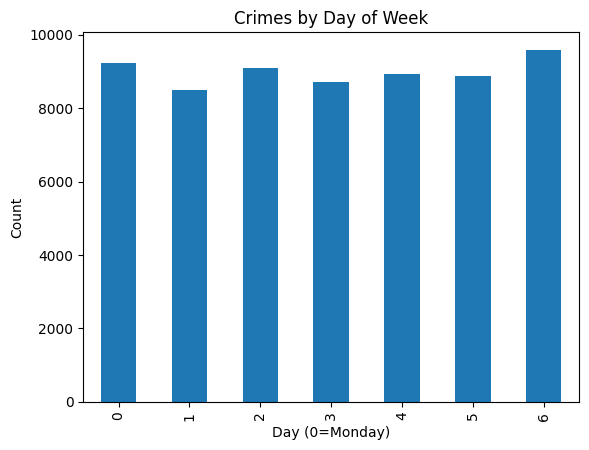

In [ ]:
# Plot crimes for each weekday
df['weekday'].value_counts().sort_index().plot(kind='bar')
plt.title("Crimes by Day of Week")
plt.xlabel("Day (0=Monday)")
plt.ylabel("Count")
plt.show()

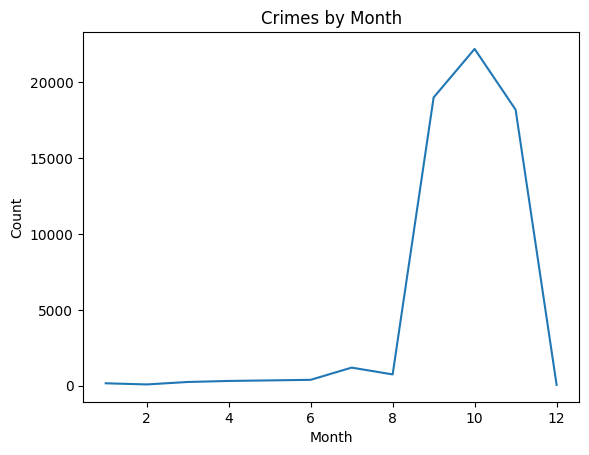

In [ ]:
# Plot crimes per month
df['month'].value_counts().sort_index().plot(kind='line')
plt.title("Crimes by Month")
plt.xlabel("Month")
plt.ylabel("Count")
plt.show()

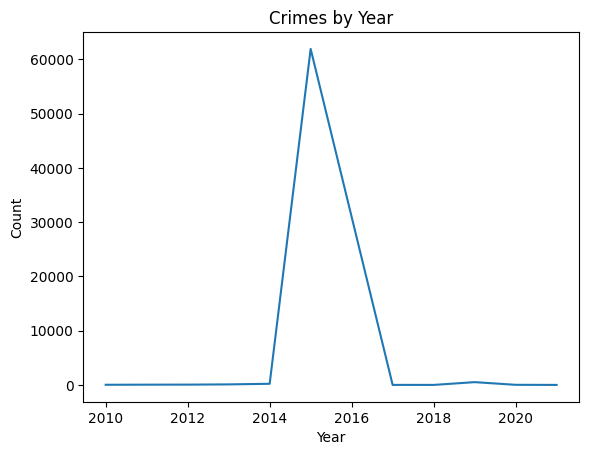

In [ ]:
# Plot crimes per year
df['year'].value_counts().sort_index().plot(kind='line')
plt.title("Crimes by Year")
plt.xlabel("Year")
plt.ylabel("Count")
plt.show()

/tmp/ipykernel_7280/4090567957.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df.set_index('date').resample('M').size().plot()


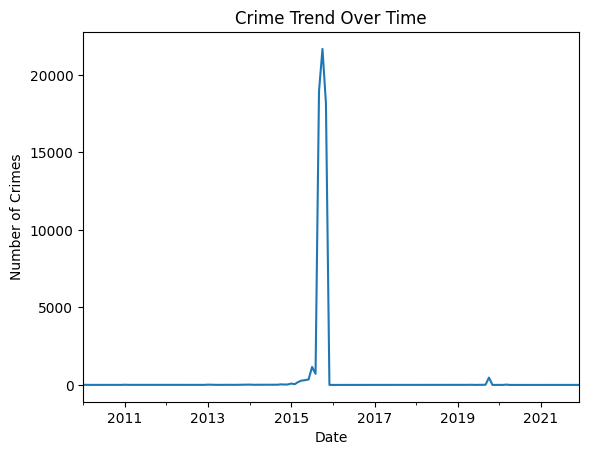

In [ ]:
# Analyze crime trend over time
df.set_index('date').resample('M').size().plot()
plt.title("Crime Trend Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Crimes")
plt.show()

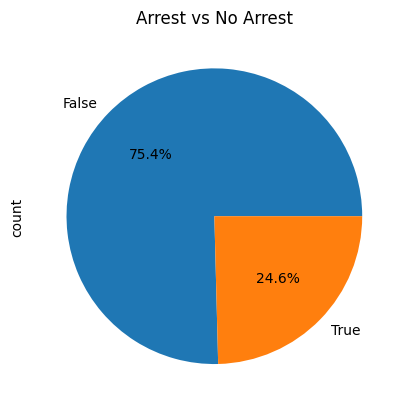

In [ ]:
# Show proportion of arrests
df['arrest'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title("Arrest vs No Arrest")
plt.show()

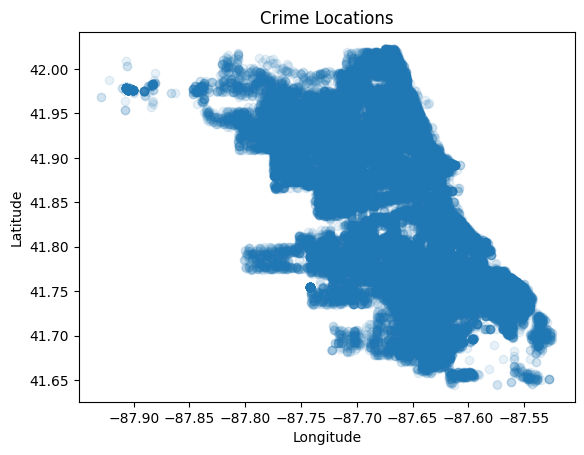

In [ ]:
# Plot crime locations
plt.scatter(df['long'], df['lat'], alpha=0.1)
plt.title("Crime Locations")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

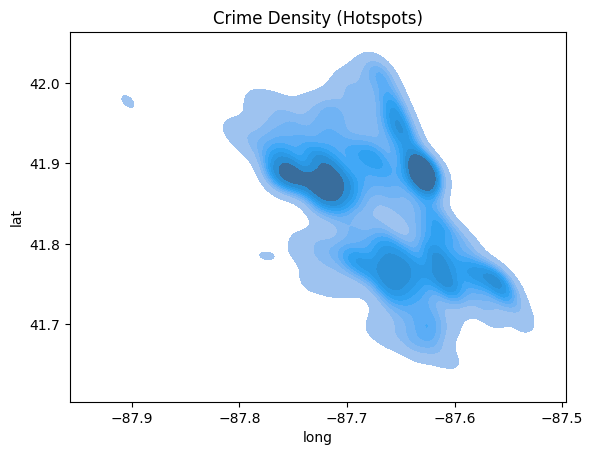

In [ ]:
# Plot density of crime locations
sns.kdeplot(x=df['long'], y=df['lat'], fill=True)
plt.title("Crime Density (Hotspots)")
plt.show()

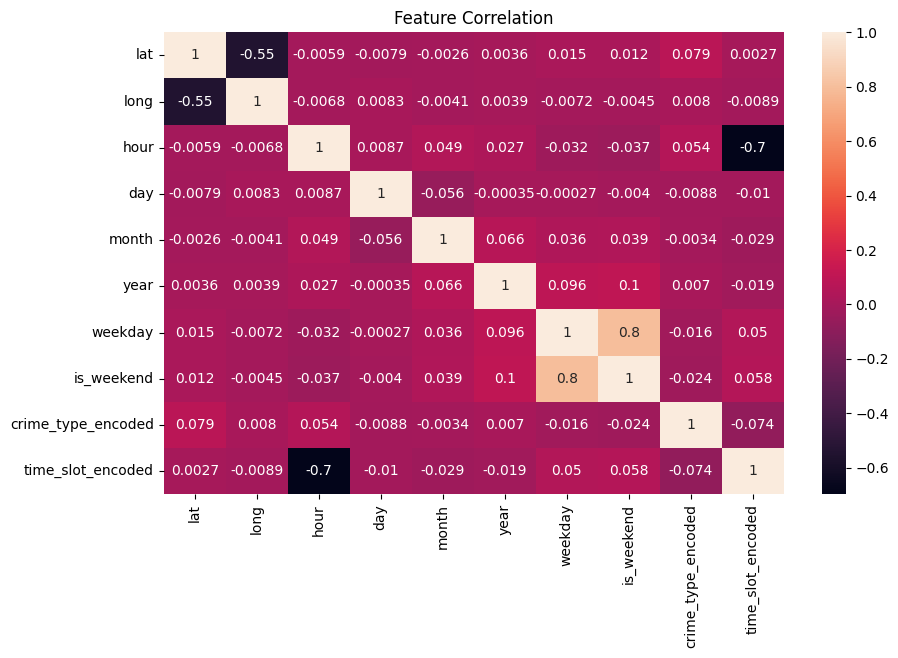

In [ ]:
# Show correlation between numerical features
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.title("Feature Correlation")
plt.show()

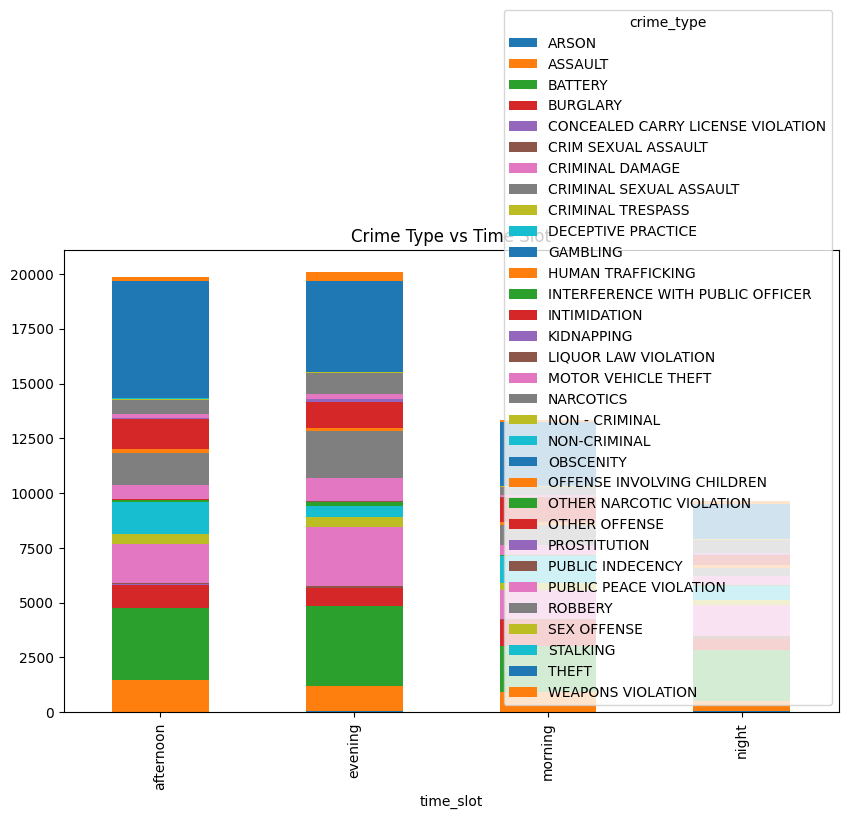

In [ ]:
# Compare crime types across time slots
ct = pd.crosstab(df['time_slot'], df['crime_type'])
ct.head().plot(kind='bar', stacked=True, figsize=(10,6))
plt.title("Crime Type vs Time Slot")
plt.show()

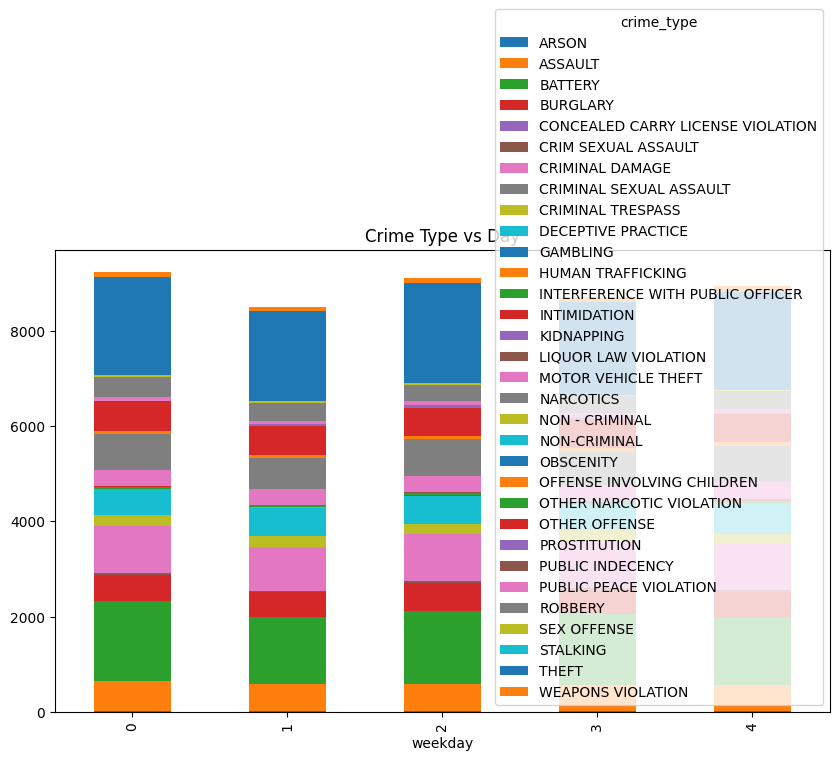

In [ ]:
# Compare crime types across weekdays
ct2 = pd.crosstab(df['weekday'], df['crime_type'])
ct2.head().plot(kind='bar', stacked=True, figsize=(10,6))
plt.title("Crime Type vs Day")
plt.show()

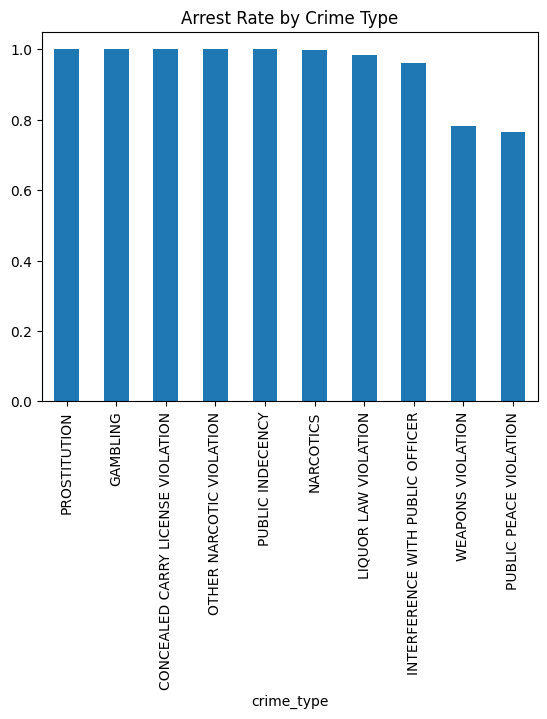

In [ ]:
# Calculate arrest rate per crime type
arrest_rate = df.groupby('crime_type')['arrest'].mean().sort_values(ascending=False)

# Plot top 10
arrest_rate.head(10).plot(kind='bar')
plt.title("Arrest Rate by Crime Type")
plt.show()

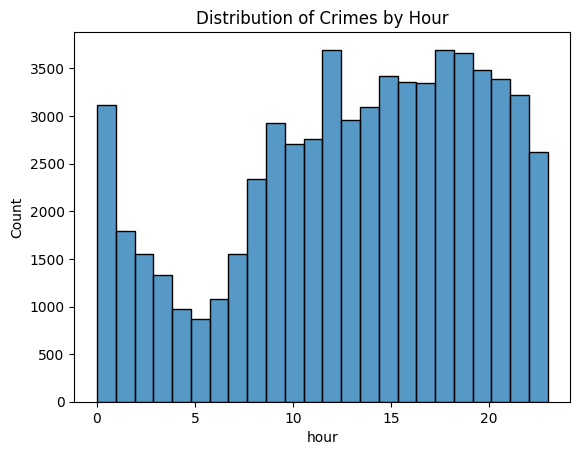

In [ ]:
# Plot histogram of crime hours
sns.histplot(df['hour'], bins=24)
plt.title("Distribution of Crimes by Hour")
plt.show()

In [ ]:
# Check skewness of numerical features
print(df[['hour','month']].skew())

hour    -0.458829
month   -2.559231
dtype: float64


In [ ]:
# Find top 10 locations with highest crime count
top_locations = df.groupby(['lat','long']).size().reset_index(name='count')
top_locations = top_locations.sort_values(by='count', ascending=False).head(10)

print(top_locations)

             lat       long  count
28046  41.883500 -87.627877    111
8664   41.754593 -87.741529     74
6094   41.742710 -87.634088     62
31127  41.897895 -87.624097     54
33530  41.909664 -87.742729     52
42420  41.976290 -87.905227     49
42627  41.979006 -87.906463     48
24323  41.868542 -87.639235     39
42460  41.976763 -87.900984     39
33020  41.907153 -87.639681     35


=== Crime Clustering Analysis ===

Feature matrix shape: (50000, 8)

--- Elbow Method (finding optimal K) ---
  K=2  |  Inertia=318066  |  Silhouette=0.2336
  K=3  |  Inertia=269086  |  Silhouette=0.2158
  K=4  |  Inertia=242189  |  Silhouette=0.1851
  K=5  |  Inertia=217775  |  Silhouette=0.2114
  K=6  |  Inertia=198297  |  Silhouette=0.2201
  K=7  |  Inertia=185101  |  Silhouette=0.2167
  K=8  |  Inertia=173276  |  Silhouette=0.2080
  K=9  |  Inertia=162905  |  Silhouette=0.2057
  K=10  |  Inertia=155968  |  Silhouette=0.1948
  K=11  |  Inertia=149719  |  Silhouette=0.1991


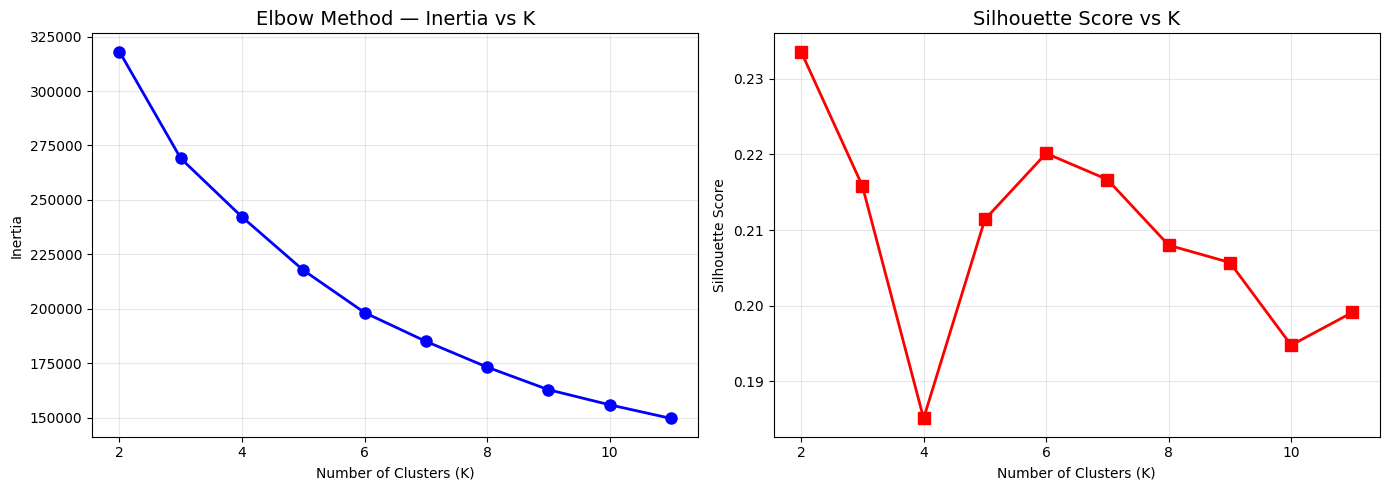


Best K by Silhouette Score: 2

--- KMeans Clustering with K=2 ---
  Silhouette Score : 0.2336  (higher is better, max=1)
  Davies-Bouldin   : 1.7144  (lower is better)


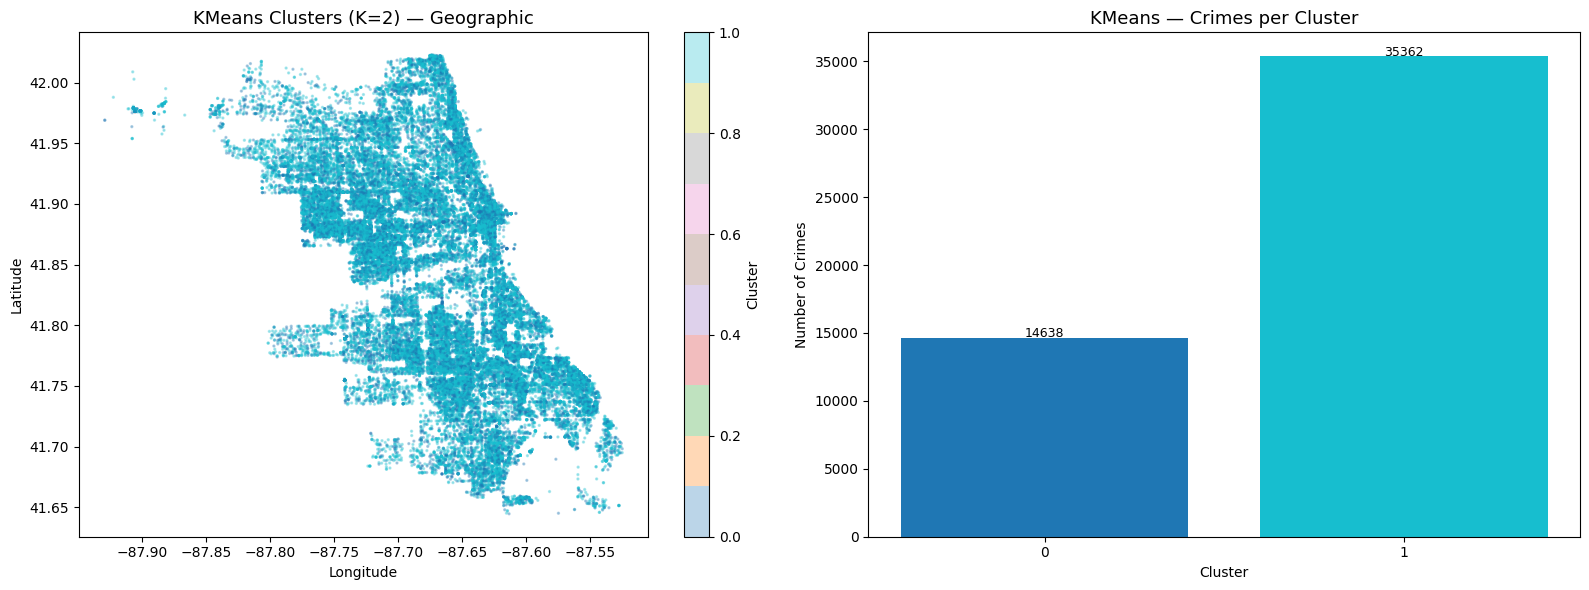


--- KMeans Cluster Profiles ---
                 hour  weekday  month  is_weekend  crime_type_encoded    lat   long
kmeans_cluster                                                                     
0               12.87     5.52   9.85         1.0               13.93  41.84 -87.67
1               13.38     1.99   9.73         0.0               14.57  41.84 -87.67


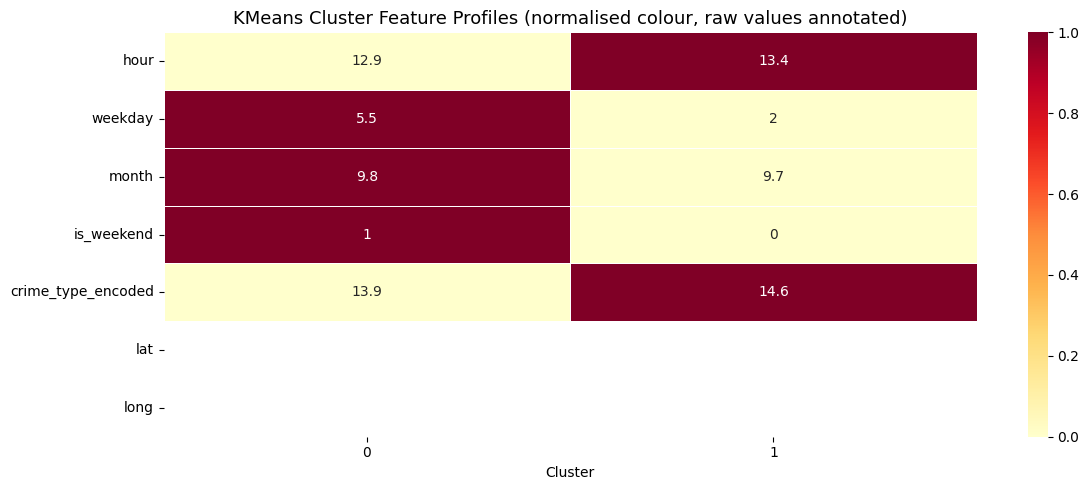


Most Common Crime Type per Cluster:
  Cluster 0: THEFT  (3133 crimes)
  Cluster 1: THEFT  (7928 crimes)

--- DBSCAN Hotspot Detection ---
  DBSCAN Hotspots Found : 70
  Points in Hotspots    : 42861 (85.7%)
  Noise Points          : 7139


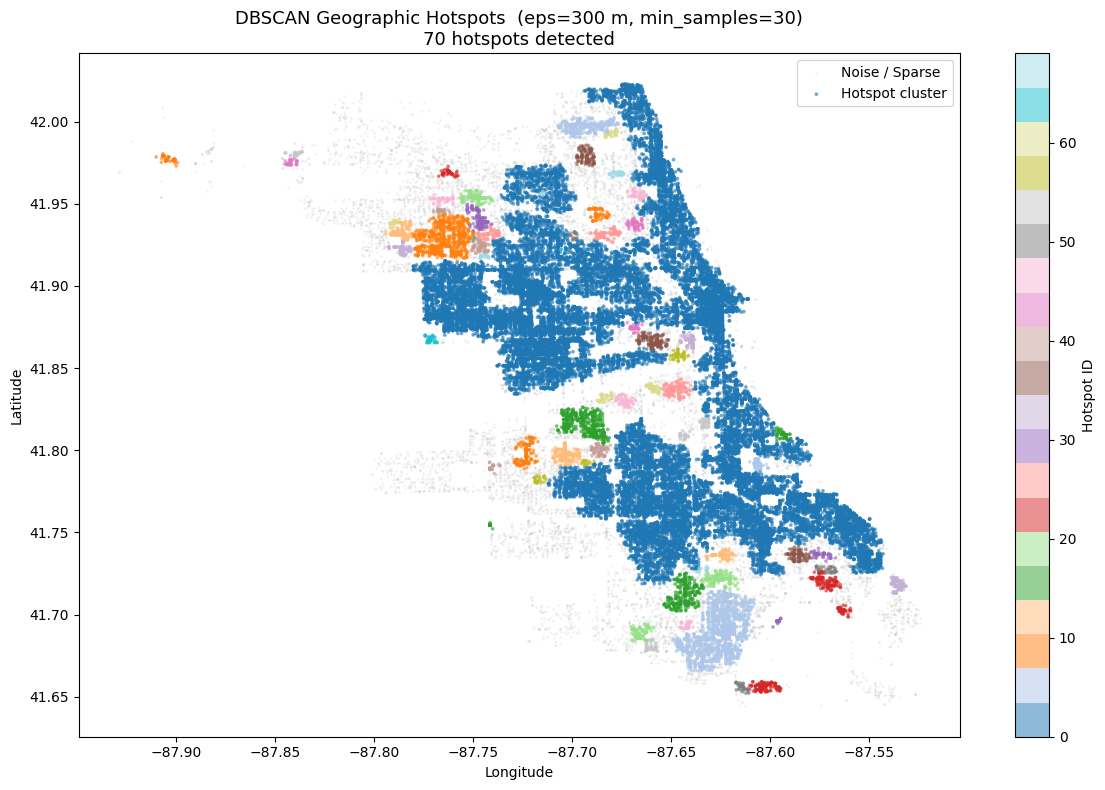


Top 10 DBSCAN Hotspots:
                crime_count  centre_lat  centre_lon
dbscan_cluster                                     
0                     14527   41.772036  -87.627056
1                     12817   41.886817  -87.718594
2                      7460   41.921391  -87.642786
4                      1378   41.689833  -87.626061
3                       847   41.960170  -87.716092
9                       640   41.929051  -87.764273
15                      414   41.815876  -87.693814
5                       297   41.996888  -87.692812
14                      293   41.712111  -87.643610
20                      207   41.721364  -87.625191


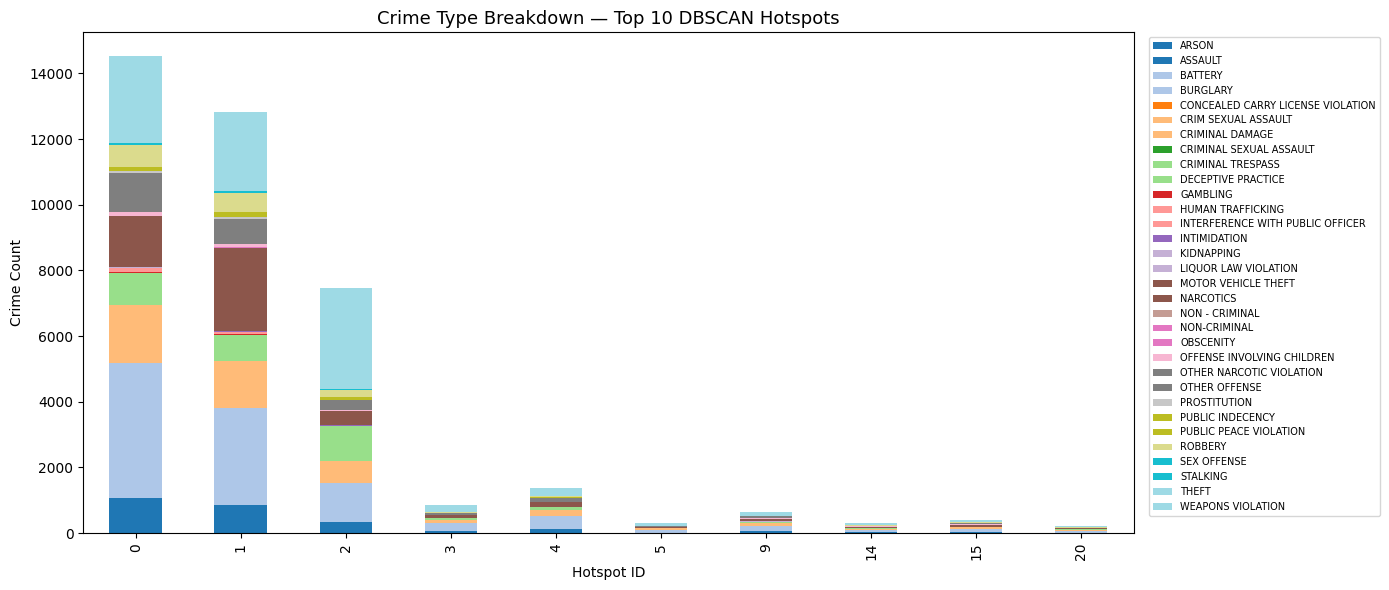

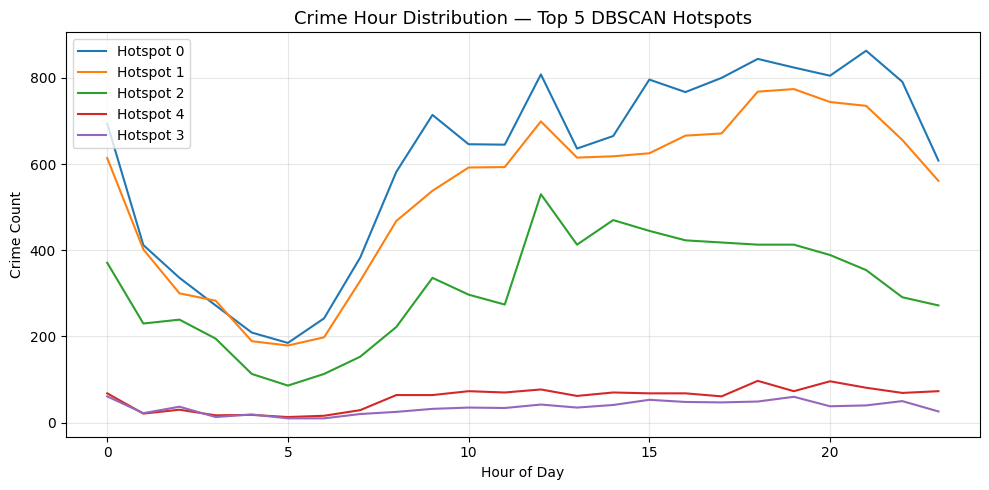


--- Patrol Recommendations by Cluster & Time Slot ---


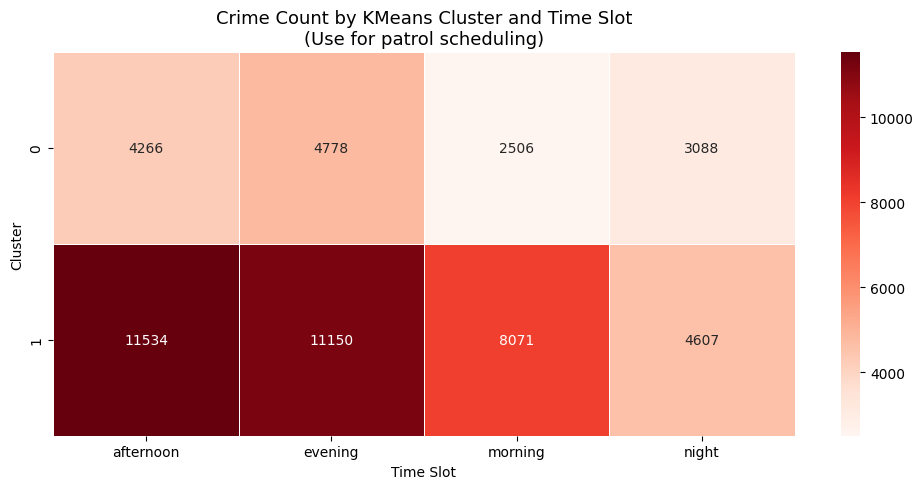


Peak patrol time per cluster:
  Cluster 0 | Peak: evening      (4778 crimes) | Centre ≈ (41.8438, -87.6721)
  Cluster 1 | Peak: afternoon    (11534 crimes) | Centre ≈ (41.8426, -87.6720)

           CLUSTERING SUMMARY
  Algorithm       : KMeans
  Optimal K       : 2
  Silhouette Score: 0.2336
  Davies-Bouldin  : 1.7144

  Algorithm       : DBSCAN (Geo-hotspot)
  Hotspots Found  : 70
  Coverage        : 85.7% of crimes in hotspots

Cluster-labelled dataframe ready: (50000, 10)
         lat       long  hour  weekday  month           crime_type  time_slot  \
0  41.777052 -87.665421    17        4     10   DECEPTIVE PRACTICE  afternoon   
1  41.764941 -87.632201    15        6     10             BURGLARY  afternoon   
2  41.938310 -87.639486    14        2     10   DECEPTIVE PRACTICE  afternoon   
3  41.899769 -87.728674    22        5      9  MOTOR VEHICLE THEFT    evening   
4  41.883500 -87.627877    17        4     11                THEFT  afternoon   

   is_weekend  kmeans_cluster  

In [ ]:
#CLUSTERING - ADITYA
# ============================================================
# SECTION 1: SETUP & FEATURE PREPARATION
# ============================================================
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

print("=== Crime Clustering Analysis ===\n")

# Sample for performance (use full data if you have enough RAM)
sample_df = df.sample(n=min(50000, len(df)), random_state=42).reset_index(drop=True)

# Features used for clustering
features = ['lat', 'long', 'hour', 'weekday', 'month', 'crime_type_encoded', 'time_slot_encoded', 'is_weekend']
X = sample_df[features].copy()

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(f"Feature matrix shape: {X_scaled.shape}")


# ============================================================
# SECTION 2: ELBOW METHOD — Find Optimal K for KMeans
# ============================================================
print("\n--- Elbow Method (finding optimal K) ---")
inertias = []
sil_scores = []
k_range = range(2, 12)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, km.labels_, sample_size=5000, random_state=42))
    print(f"  K={k}  |  Inertia={km.inertia_:.0f}  |  Silhouette={sil_scores[-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_range), inertias, 'bo-', linewidth=2, markersize=8)
axes[0].set_title("Elbow Method — Inertia vs K", fontsize=14)
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].grid(True, alpha=0.3)

axes[1].plot(list(k_range), sil_scores, 'rs-', linewidth=2, markersize=8)
axes[1].set_title("Silhouette Score vs K", fontsize=14)
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("elbow_silhouette.png", dpi=150, bbox_inches='tight')
plt.show()

optimal_k = list(k_range)[sil_scores.index(max(sil_scores))]
print(f"\nBest K by Silhouette Score: {optimal_k}")


# ============================================================
# SECTION 3: KMeans CLUSTERING
# ============================================================
print(f"\n--- KMeans Clustering with K={optimal_k} ---")
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
sample_df['kmeans_cluster'] = kmeans.fit_predict(X_scaled)

km_sil  = silhouette_score(X_scaled, sample_df['kmeans_cluster'], sample_size=5000, random_state=42)
km_db   = davies_bouldin_score(X_scaled, sample_df['kmeans_cluster'])
print(f"  Silhouette Score : {km_sil:.4f}  (higher is better, max=1)")
print(f"  Davies-Bouldin   : {km_db:.4f}  (lower is better)")

# KMeans — Geo scatter
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
scatter = axes[0].scatter(
    sample_df['long'], sample_df['lat'],
    c=sample_df['kmeans_cluster'], cmap='tab10', alpha=0.3, s=2
)
axes[0].set_title(f"KMeans Clusters (K={optimal_k}) — Geographic", fontsize=13)
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
plt.colorbar(scatter, ax=axes[0], label="Cluster")

# KMeans — Cluster size bar chart
cluster_counts = sample_df['kmeans_cluster'].value_counts().sort_index()
axes[1].bar(cluster_counts.index.astype(str), cluster_counts.values,
            color=plt.cm.tab10(np.linspace(0, 1, optimal_k)))
axes[1].set_title("KMeans — Crimes per Cluster", fontsize=13)
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Number of Crimes")
for i, v in enumerate(cluster_counts.values):
    axes[1].text(i, v + 50, str(v), ha='center', fontsize=9)

plt.tight_layout()
plt.savefig("kmeans_clusters.png", dpi=150, bbox_inches='tight')
plt.show()


# ============================================================
# SECTION 4: KMeans CLUSTER PROFILES
# ============================================================
print("\n--- KMeans Cluster Profiles ---")
profile_cols = ['hour', 'weekday', 'month', 'is_weekend', 'crime_type_encoded', 'lat', 'long']
cluster_profile = sample_df.groupby('kmeans_cluster')[profile_cols].mean().round(2)
print(cluster_profile.to_string())

# Heatmap of cluster profiles
plt.figure(figsize=(12, 5))
profile_norm = (cluster_profile - cluster_profile.min()) / (cluster_profile.max() - cluster_profile.min())
sns.heatmap(profile_norm.T, annot=cluster_profile.T.round(1), fmt='g',
            cmap='YlOrRd', linewidths=0.5)
plt.title("KMeans Cluster Feature Profiles (normalised colour, raw values annotated)", fontsize=13)
plt.xlabel("Cluster")
plt.tight_layout()
plt.savefig("kmeans_profile_heatmap.png", dpi=150, bbox_inches='tight')
plt.show()

# Top crime type per cluster
print("\nMost Common Crime Type per Cluster:")
for c in sorted(sample_df['kmeans_cluster'].unique()):
    top_crime = sample_df[sample_df['kmeans_cluster'] == c]['crime_type'].value_counts().idxmax()
    count     = sample_df[sample_df['kmeans_cluster'] == c]['crime_type'].value_counts().max()
    print(f"  Cluster {c}: {top_crime}  ({count} crimes)")


# ============================================================
# SECTION 5: DBSCAN — Geo-Spatial Hotspot Detection
# ============================================================
print("\n--- DBSCAN Hotspot Detection ---")

# Use only lat/long (scaled by approximate metres using ~111 km/degree)
geo_sample = sample_df[['lat', 'long']].copy()
geo_sample_scaled = geo_sample.copy()
geo_sample_scaled['lat']  = geo_sample['lat']  * 111000   # degrees → metres (approx)
geo_sample_scaled['long'] = geo_sample['long'] * 111000 * np.cos(np.radians(geo_sample['lat'].mean()))

# eps in metres, min_samples controls density threshold
db = DBSCAN(eps=300, min_samples=30, algorithm='ball_tree', metric='euclidean')
sample_df['dbscan_cluster'] = db.fit_predict(geo_sample_scaled)

n_hotspots  = len(set(sample_df['dbscan_cluster'])) - (1 if -1 in sample_df['dbscan_cluster'].values else 0)
n_noise     = (sample_df['dbscan_cluster'] == -1).sum()
n_clustered = (sample_df['dbscan_cluster'] != -1).sum()

print(f"  DBSCAN Hotspots Found : {n_hotspots}")
print(f"  Points in Hotspots    : {n_clustered} ({100*n_clustered/len(sample_df):.1f}%)")
print(f"  Noise Points          : {n_noise}")

# DBSCAN Geo Plot
plt.figure(figsize=(12, 8))
noise_mask = sample_df['dbscan_cluster'] == -1
plt.scatter(sample_df.loc[noise_mask, 'long'],
            sample_df.loc[noise_mask, 'lat'],
            c='lightgrey', alpha=0.2, s=1, label='Noise / Sparse')
scatter = plt.scatter(sample_df.loc[~noise_mask, 'long'],
                      sample_df.loc[~noise_mask, 'lat'],
                      c=sample_df.loc[~noise_mask, 'dbscan_cluster'],
                      cmap='tab20', alpha=0.5, s=3, label='Hotspot cluster')
plt.colorbar(scatter, label='Hotspot ID')
plt.title(f"DBSCAN Geographic Hotspots  (eps=300 m, min_samples=30)\n{n_hotspots} hotspots detected", fontsize=13)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig("dbscan_hotspots.png", dpi=150, bbox_inches='tight')
plt.show()

# Top 10 hotspots by crime count
print("\nTop 10 DBSCAN Hotspots:")
hotspot_sizes = (sample_df[sample_df['dbscan_cluster'] != -1]
                  .groupby('dbscan_cluster')
                  .agg(crime_count=('lat','count'),
                       centre_lat=('lat','mean'),
                       centre_lon=('long','mean'))
                  .sort_values('crime_count', ascending=False)
                  .head(10))
print(hotspot_sizes.to_string())


# ============================================================
# SECTION 6: DBSCAN HOTSPOT PROFILES
# ============================================================
top10_ids = hotspot_sizes.index.tolist()
top10_df  = sample_df[sample_df['dbscan_cluster'].isin(top10_ids)].copy()

# Crime type distribution in top 10 hotspots
fig, ax = plt.subplots(figsize=(14, 6))
hotspot_crime = (top10_df.groupby(['dbscan_cluster', 'crime_type'])
                          .size()
                          .reset_index(name='count'))
pivot = hotspot_crime.pivot(index='dbscan_cluster', columns='crime_type', values='count').fillna(0)
pivot.plot(kind='bar', stacked=True, ax=ax, colormap='tab20', legend=True)
ax.set_title("Crime Type Breakdown — Top 10 DBSCAN Hotspots", fontsize=13)
ax.set_xlabel("Hotspot ID")
ax.set_ylabel("Crime Count")
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=7)
plt.tight_layout()
plt.savefig("dbscan_hotspot_crime_types.png", dpi=150, bbox_inches='tight')
plt.show()

# Hour-of-day distribution for top 10 hotspots
plt.figure(figsize=(10, 5))
for hid in top10_ids[:5]:   # top 5 for clarity
    subset = top10_df[top10_df['dbscan_cluster'] == hid]
    subset['hour'].value_counts().sort_index().plot(kind='line', label=f'Hotspot {hid}')
plt.title("Crime Hour Distribution — Top 5 DBSCAN Hotspots", fontsize=13)
plt.xlabel("Hour of Day")
plt.ylabel("Crime Count")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("dbscan_hotspot_hours.png", dpi=150, bbox_inches='tight')
plt.show()


# ============================================================
# SECTION 7: KMeans CLUSTER vs TIME SLOT — PATROL INSIGHT
# ============================================================
print("\n--- Patrol Recommendations by Cluster & Time Slot ---")
patrol = (sample_df.groupby(['kmeans_cluster', 'time_slot'])
                   .size()
                   .reset_index(name='crime_count'))
patrol_pivot = patrol.pivot(index='kmeans_cluster', columns='time_slot', values='crime_count').fillna(0)

plt.figure(figsize=(10, 5))
sns.heatmap(patrol_pivot, annot=True, fmt='.0f', cmap='Reds', linewidths=0.5)
plt.title("Crime Count by KMeans Cluster and Time Slot\n(Use for patrol scheduling)", fontsize=13)
plt.xlabel("Time Slot")
plt.ylabel("Cluster")
plt.tight_layout()
plt.savefig("patrol_heatmap.png", dpi=150, bbox_inches='tight')
plt.show()

print("\nPeak patrol time per cluster:")
for c in sorted(patrol_pivot.index):
    peak_slot = patrol_pivot.loc[c].idxmax()
    peak_val  = int(patrol_pivot.loc[c].max())
    lat_c = sample_df[sample_df['kmeans_cluster'] == c]['lat'].mean()
    lon_c = sample_df[sample_df['kmeans_cluster'] == c]['long'].mean()
    print(f"  Cluster {c} | Peak: {peak_slot:12s} ({peak_val} crimes) | Centre ≈ ({lat_c:.4f}, {lon_c:.4f})")


# ============================================================
# SECTION 8: CLUSTERING SUMMARY
# ============================================================
print("\n" + "="*55)
print("           CLUSTERING SUMMARY")
print("="*55)
print(f"  Algorithm       : KMeans")
print(f"  Optimal K       : {optimal_k}")
print(f"  Silhouette Score: {km_sil:.4f}")
print(f"  Davies-Bouldin  : {km_db:.4f}")
print(f"")
print(f"  Algorithm       : DBSCAN (Geo-hotspot)")
print(f"  Hotspots Found  : {n_hotspots}")
print(f"  Coverage        : {100*n_clustered/len(sample_df):.1f}% of crimes in hotspots")
print("="*55)

# Attach cluster labels back to main df (for downstream prediction step)
sample_df_export = sample_df[['lat','long','hour','weekday','month',
                               'crime_type','time_slot','is_weekend',
                               'kmeans_cluster','dbscan_cluster']].copy()
print(f"\nCluster-labelled dataframe ready: {sample_df_export.shape}")
print(sample_df_export.head())


In [43]:
# =====================================
# PREDICTION + NOVELTY
# =====================================
df = df.sample(n=250000, random_state=42).reset_index(drop=True)
from sklearn.cluster import KMeans
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
import pandas as pd
import numpy as np

# -------------------------------
# 1. MICRO-ZONE CLUSTERING
# -------------------------------
kmeans = KMeans(n_clusters=5, random_state=42)
df['zone'] = kmeans.fit_predict(df[['lat', 'long']])

# -------------------------------
# 2. DENSITY FEATURES
# -------------------------------
zone_counts = df['zone'].value_counts().to_dict()
df['zone_density'] = df['zone'].map(zone_counts) / df['zone'].value_counts().max()

time_counts = df['time_slot'].value_counts().to_dict()
df['time_density'] = df['time_slot'].map(time_counts) / df['time_slot'].value_counts().max()

# -------------------------------
# 3. INTERACTION FEATURE
# -------------------------------
df['zone_time'] = df['zone'].astype(str) + "_" + df['time_slot']
le2 = LabelEncoder()
df['zone_time_encoded'] = le2.fit_transform(df['zone_time'])

# -------------------------------
# 4. SEVERITY
# -------------------------------
severity_map = {'THEFT': 2, 'BATTERY': 4, 'ASSAULT': 4, 'ROBBERY': 5, 'HOMICIDE': 5}
df['severity'] = df['crime_type'].map(severity_map).fillna(1)

# -------------------------------
# 5. TARGET-ENCODED FEATURES
#    (encode BEFORE split using full df — acceptable for small datasets)
# -------------------------------
zone_arrest_rate    = df.groupby('zone')['arrest'].mean().to_dict()
hour_arrest_rate    = df.groupby('hour')['arrest'].mean().to_dict()
crime_arrest_rate   = df.groupby('crime_type')['arrest'].mean().to_dict()
weekday_arrest_rate = df.groupby('weekday')['arrest'].mean().to_dict()
slot_arrest_rate    = df.groupby('time_slot')['arrest'].mean().to_dict()

df['zone_arrest_rate']    = df['zone'].map(zone_arrest_rate)
df['hour_arrest_rate']    = df['hour'].map(hour_arrest_rate)
df['crime_arrest_rate']   = df['crime_type'].map(crime_arrest_rate)
df['weekday_arrest_rate'] = df['weekday'].map(weekday_arrest_rate)
df['slot_arrest_rate']    = df['time_slot'].map(slot_arrest_rate)

# NEW: combined interaction rates
df['zone_hour_key'] = df['zone'].astype(str) + "_" + df['hour'].astype(str)
zone_hour_rate = df.groupby('zone_hour_key')['arrest'].mean().to_dict()
df['zone_hour_arrest_rate'] = df['zone_hour_key'].map(zone_hour_rate).fillna(df['zone_arrest_rate'])

# -------------------------------
# 6. FINAL FEATURES
# -------------------------------
features = [
    'lat', 'long',
    'hour', 'month', 'weekday', 'day',
    'is_weekend',
    'zone',
    'zone_density',
    'time_density',
    'zone_time_encoded',
    'severity',
    'crime_type_encoded',
    'time_slot_encoded',
    'zone_arrest_rate',
    'hour_arrest_rate',
    'crime_arrest_rate',
    'weekday_arrest_rate',
    'slot_arrest_rate',
    'zone_hour_arrest_rate',   # ← new interaction
]

X = df[features]
y = df['arrest'].astype(int)

# -------------------------------
# 7. TRAIN / TEST SPLIT
# -------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# -------------------------------
# 8. SMOTE ON TRAIN ONLY
# -------------------------------
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

# -------------------------------
# 9. STACKING ENSEMBLE
#    RF + XGBoost + GBM → Logistic Regression meta-learner
# -------------------------------
scale = (y_train_bal == 0).sum() / (y_train_bal == 1).sum()

estimators = [
    ('rf', RandomForestClassifier(
        n_estimators=500,
        max_depth=10,
        class_weight='balanced',
        random_state=42
    )),
    ('xgb', XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        gamma=1,
        min_child_weight=3,
        random_state=42,
        eval_metric='auc'
    )),
    ('gbm', GradientBoostingClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        random_state=42
    ))
]

model = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(C=1.0),
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    passthrough=False,
    n_jobs=-1
)

print("Training stacking ensemble... (may take 1-2 minutes)")
model.fit(X_train_bal, y_train_bal)

# -------------------------------
# 10. EVALUATION
# -------------------------------
y_pred  = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("\n=== MODEL PERFORMANCE ===")
print("Accuracy :", accuracy_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_proba))

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred,
                             target_names=['No Arrest', 'Arrest'],
                             zero_division=0))

# ===============================
# NOVELTY OUTPUT
# ===============================

# -------------------------------
# 11. ARREST LIKELIHOOD ON FULL DATA
# -------------------------------
df['arrest_probability'] = model.predict_proba(X)[:, 1]

def arrest_likelihood_label(prob):
    if prob > 0.66:
        return "High Likelihood"
    elif prob > 0.33:
        return "Medium Likelihood"
    else:
        return "Low Likelihood"

df['arrest_likelihood'] = df['arrest_probability'].apply(arrest_likelihood_label)

# -------------------------------
# 12. PATROL DECISION TABLE
# -------------------------------
decision_table = df.groupby(['zone', 'time_slot']).agg(
    avg_arrest_prob=('arrest_probability', 'mean'),
    crime_count=('arrest_probability', 'count')
).reset_index()

decision_table['arrest_likelihood'] = decision_table['avg_arrest_prob'].apply(
    arrest_likelihood_label
)

print("\n=== PATROL DECISION TABLE ===")
print(decision_table.sort_values('avg_arrest_prob', ascending=False).head(10))

# -------------------------------
# 13. SAMPLE OUTPUT
# -------------------------------
print("\n=== SAMPLE OUTPUT ===")
print(df[['zone', 'time_slot', 'arrest_probability', 'arrest_likelihood']].head(10))

Training stacking ensemble... (may take 1-2 minutes)

=== MODEL PERFORMANCE ===
Accuracy : 0.86722
ROC-AUC  : 0.8223125645478889

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

   No Arrest       0.87      0.98      0.92     38950
      Arrest       0.86      0.47      0.61     11050

    accuracy                           0.87     50000
   macro avg       0.87      0.73      0.77     50000
weighted avg       0.87      0.87      0.85     50000


=== PATROL DECISION TABLE ===
    zone  time_slot  avg_arrest_prob  crime_count  arrest_likelihood
17     4    evening         0.336574        22115  Medium Likelihood
9      2    evening         0.305603        14591     Low Likelihood
16     4  afternoon         0.301275        19855     Low Likelihood
18     4    morning         0.295468        14082     Low Likelihood
1      0    evening         0.292593         8937     Low Likelihood
13     3    evening         0.280087        14478     Low Likelihood